# Olist marketplace: growth, customer experience and early delivery risk

This notebook uses the nine supplied CSV files. All monetary amounts are BRL.
The business objective is to grow merchandise sales while reducing avoidable
delivery failures. Revenue means delivered merchandise GMV, not Olist's net
revenue or profit. Payments include freight and cannot be used interchangeably.

Run cells in order. Outputs are written under `results/`. The report uses the
historical dataset period, not today's business performance.

In [1]:
from pathlib import Path
import json, hashlib, sqlite3, warnings
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score, average_precision_score,
    confusion_matrix, precision_recall_curve, brier_score_loss)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
import joblib

ROOT = Path.cwd()
if not (ROOT / 'data/raw').exists():
    ROOT = ROOT.parent
RAW = ROOT / 'data/raw'
OUT = ROOT / 'results'
TABLES = OUT / 'tables'
TABLES.mkdir(parents=True, exist_ok=True)
SEED = 2026
pd.set_option('display.max_columns', 16)

def show(x):
    try:
        from IPython.display import display
        display(x)
    except ImportError:
        print(x)

def save_table(name, frame):
    frame.to_csv(TABLES / f'{name}.csv', index=False)
    return frame

## 1. Source integrity and data grain

Orders have one row per order. Items and payments have multiple rows per order.
Reviews can also have multiple rows per order. Aggregate each independently
before joining. Customers' `customer_unique_id` identifies repeat purchasers.
ZIP prefixes stay as five-character strings. Geolocation is a many-row lookup,
so reduce it to one median coordinate pair per ZIP before joining.

In [2]:
names = ['customers','orders','order_items','order_payments','order_reviews',
         'products','sellers','geolocation']
raw = {n: pd.read_csv(RAW / f'olist_{n}_dataset.csv',
        dtype={c:'string' for c in ['customer_zip_code_prefix',
               'seller_zip_code_prefix','geolocation_zip_code_prefix']}) for n in names}
raw['translation'] = pd.read_csv(RAW / 'product_category_name_translation.csv')
profile = []
missing = []
for name, frame in raw.items():
    profile.append({'table':name,'rows':len(frame),'columns':len(frame.columns),
                    'exact_duplicates':int(frame.duplicated().sum())})
    for col in frame.columns:
        if frame[col].isna().any():
            missing.append({'table':name,'column':col,'missing':int(frame[col].isna().sum()),
                            'missing_pct':100*frame[col].isna().mean()})
save_table('data_profile', pd.DataFrame(profile))
save_table('missing_values', pd.DataFrame(missing))
show(pd.DataFrame(profile))
for item in json.loads((ROOT/'data/source_manifest.json').read_text()):
    assert hashlib.sha256((RAW/item['name']).read_bytes()).hexdigest()==item['sha256']
# Explicit assignments make the order of tables unambiguous.
o=raw['orders'].copy(); c=raw['customers'].copy(); i=raw['order_items'].copy()
p=raw['order_payments'].copy(); r=raw['order_reviews'].copy()
pr=raw['products'].copy(); s=raw['sellers'].copy(); g=raw['geolocation'].copy()
assert o.order_id.is_unique and c.customer_id.is_unique
assert pr.product_id.is_unique and s.seller_id.is_unique
assert not i.duplicated(['order_id','order_item_id']).any()
for frame in [o,i,p,r]:
    if frame is not o:
        assert frame.order_id.isin(o.order_id).all()
assert i.product_id.isin(pr.product_id).all()
assert i.seller_id.isin(s.seller_id).all()
assert o.customer_id.isin(c.customer_id).all()
for col in o.columns:
    if col.endswith('_timestamp') or col.endswith('_date') or col=='order_approved_at':
        o[col]=pd.to_datetime(o[col],errors='coerce')
for col in ['review_creation_date','review_answer_timestamp']:
    r[col]=pd.to_datetime(r[col],errors='coerce')
for frame,col in [(c,'customer_zip_code_prefix'),(s,'seller_zip_code_prefix'),
                  (g,'geolocation_zip_code_prefix')]:
    frame[col]=frame[col].str.zfill(5)
assert (i[['price','freight_value']]>=0).all().all()
assert (p.payment_value>=0).all()

,table,rows,columns,exact_duplicates
0,customers,99441,5,0
1,orders,99441,8,0
2,order_items,112650,7,0
3,order_payments,103886,5,0
4,order_reviews,99224,7,0
5,products,32951,9,0
6,sellers,3095,4,0
7,geolocation,1000163,5,261831
8,translation,71,2,0


## 2. Cleaning and safe joins

No blanket row deletion or revenue imputation. Missing product categories become
`unknown`. Preserve untranslated category names explicitly. Zero or missing
physical dimensions become missing measurements and receive train-only median
imputation in ML. Coordinates outside a broad Brazil bounding box are excluded.

For satisfaction, use the latest answered review per order (stable ID tie-break).
Sensitivity analysis repeats the comparison using the mean of all order reviews.
Delivery eligibility requires status delivered, actual and estimated timestamps,
and delivery no earlier than purchase. Exact timestamp comparison follows the
assessment. A calendar-day sensitivity addresses midnight estimated dates.

In [3]:
pr=pr.merge(raw['translation'],on='product_category_name',how='left',validate='m:1')
pr['category']=pr.product_category_name_english.fillna(
    pr.product_category_name.map(lambda x: 'untranslated_'+str(x) if pd.notna(x) else 'unknown'))
for col in ['product_weight_g','product_length_cm','product_height_cm','product_width_cm']:
    pr.loc[pr[col]<=0,col]=np.nan
pr['product_volume_cm3']=pr.product_length_cm*pr.product_height_cm*pr.product_width_cm
geo_duplicate_count=int(g.duplicated().sum())
g=g.drop_duplicates()
valid_geo=g.geolocation_lat.between(-35,6)&g.geolocation_lng.between(-74,-34)
geo_invalid_count=int((~valid_geo).sum())
geo=g.loc[valid_geo].groupby('geolocation_zip_code_prefix',as_index=False).agg(
    lat=('geolocation_lat','median'),lon=('geolocation_lng','median'))
c=c.merge(geo.rename(columns={'geolocation_zip_code_prefix':'customer_zip_code_prefix',
        'lat':'customer_lat','lon':'customer_lon'}),on='customer_zip_code_prefix',how='left',validate='m:1')
s=s.merge(geo.rename(columns={'geolocation_zip_code_prefix':'seller_zip_code_prefix',
        'lat':'seller_lat','lon':'seller_lon'}),on='seller_zip_code_prefix',how='left',validate='m:1')
items=i.merge(pr,on='product_id',how='left',validate='m:1').merge(s,on='seller_id',how='left',validate='m:1')
items=items.merge(o[['order_id','customer_id','order_status','order_purchase_timestamp']],
                  on='order_id',validate='m:1').merge(c,on='customer_id',validate='m:1')
la1=np.radians(items.customer_lat); la2=np.radians(items.seller_lat)
dl=la2-la1; dn=np.radians(items.seller_lon-items.customer_lon)
a=np.sin(dl/2)**2+np.cos(la1)*np.cos(la2)*np.sin(dn/2)**2
items['distance_km']=6371*2*np.arcsin(np.sqrt(a.clip(0,1)))
items['cross_state']=(items.customer_state!=items.seller_state).astype(int)
agg=items.groupby('order_id').agg(
    gmv=('price','sum'),freight=('freight_value','sum'),n_items=('order_item_id','count'),
    n_sellers=('seller_id','nunique'),n_categories=('category','nunique'),
    avg_item_price=('price','mean'),weight_g=('product_weight_g','sum'),
    volume_cm3=('product_volume_cm3','sum'),distance_km=('distance_km','max'),
    cross_state=('cross_state','max'))
# Keep all-missing physical aggregates as missing instead of artificial zero.
agg['weight_g']=items.groupby('order_id').product_weight_g.sum(min_count=1)
agg['volume_cm3']=items.groupby('order_id').product_volume_cm3.sum(min_count=1)
primary_category=(items.groupby(['order_id','category'],as_index=False).price.sum()
    .sort_values(['order_id','price','category'],ascending=[True,False,True])
    .drop_duplicates('order_id').set_index('order_id').category)
primary_seller=(items.groupby(['order_id','seller_id'],as_index=False).price.sum()
    .sort_values(['order_id','price','seller_id'],ascending=[True,False,True])
    .drop_duplicates('order_id').merge(s[['seller_id','seller_state']],on='seller_id',validate='m:1')
    .set_index('order_id'))
pay=p.groupby('order_id').agg(payment_total=('payment_value','sum'),
    installments=('payment_installments','max'),payment_rows=('payment_sequential','count'))
pay['payment_type']=(p.sort_values(['order_id','payment_value','payment_type'],ascending=[True,False,True])
    .drop_duplicates('order_id').set_index('order_id').payment_type)
rev=(r.sort_values(['order_id','review_answer_timestamp','review_creation_date','review_id'])
       .drop_duplicates('order_id',keep='last').set_index('order_id'))
mart=o.merge(c,on='customer_id',how='left',validate='m:1')
mart=mart.merge(agg,on='order_id',how='left',validate='1:1').merge(pay,on='order_id',how='left',validate='1:1')
mart=mart.merge(primary_category.rename('primary_category'),on='order_id',how='left',validate='1:1')
mart=mart.merge(primary_seller[['seller_id','seller_state']],on='order_id',how='left',validate='1:1')
mart=mart.merge(rev[['review_score','review_creation_date','review_answer_timestamp']],
                on='order_id',how='left',validate='1:1')
mart['mean_review_score']=mart.order_id.map(r.groupby('order_id').review_score.mean())
mart['month']=mart.order_purchase_timestamp.dt.strftime('%Y-%m')
mart['delivered']=mart.order_status.eq('delivered')
mart['delivery_eligible']=(mart.delivered & mart.order_delivered_customer_date.notna()
    & mart.order_estimated_delivery_date.notna()
    & (mart.order_delivered_customer_date>=mart.order_purchase_timestamp))
mart['late']=np.nan
mask=mart.delivery_eligible
mart.loc[mask,'late']=(mart.loc[mask,'order_delivered_customer_date']>
                     mart.loc[mask,'order_estimated_delivery_date']).astype(int)
mart['late_calendar_day']=np.nan
mart.loc[mask,'late_calendar_day']=(mart.loc[mask,'order_delivered_customer_date'].dt.normalize()>
                     mart.loc[mask,'order_estimated_delivery_date'].dt.normalize()).astype(int)
mart['delay_days']=(mart.order_delivered_customer_date-mart.order_estimated_delivery_date).dt.total_seconds()/86400
mart['delivery_days']=(mart.order_delivered_customer_date-mart.order_purchase_timestamp).dt.total_seconds()/86400
mart['promise_days']=(mart.order_estimated_delivery_date-mart.order_purchase_timestamp).dt.total_seconds()/86400
mart['freight_ratio']=mart.freight/mart.gmv.replace(0,np.nan)
mart['poor_review']=(mart.review_score<=2).where(mart.review_score.notna())
assert len(mart)==len(o) and mart.order_id.is_unique
assert np.isclose(mart.gmv.sum(),i.price.sum())
assert np.isclose(mart.freight.sum(),i.freight_value.sum())
assert np.isclose(mart.payment_total.sum(),p.payment_value.sum())
quality={
 'rows_orders':len(o),'rows_items':len(i),'rows_reviews':len(r),
 'multi_review_orders':int((r.groupby('order_id').size()>1).sum()),
 'missing_order_reviews':int(mart.review_score.isna().sum()),
 'delivered_missing_actual':int((mart.delivered&mart.order_delivered_customer_date.isna()).sum()),
 'geo_exact_duplicates_removed':geo_duplicate_count,'geo_outside_box_removed':geo_invalid_count,
 'missing_customer_coordinates':int(mart.customer_lat.isna().sum()),
 'orders_without_items':int(mart.gmv.isna().sum()),
 'orders_without_payments':int(mart.payment_total.isna().sum()),
 'delivery_before_purchase':int((mart.delay_days.notna()&(mart.delivery_days<0)).sum()),
 'approval_before_purchase':int((mart.order_approved_at<mart.order_purchase_timestamp).sum()),
 'review_created_before_delivery':int((mart.review_creation_date<mart.order_delivered_customer_date).sum()),
 'payment_reconciliation_abs_gt_1cent':int(((mart.payment_total-mart.gmv-mart.freight).abs()>.01+1e-8).sum())}
show(pd.Series(quality,name='quality audit'))

rows_orders                             99441
rows_items                             112650
rows_reviews                            99224
multi_review_orders                       547
missing_order_reviews                     768
delivered_missing_actual                    8
geo_exact_duplicates_removed           261831
geo_outside_box_removed                    31
missing_customer_coordinates              279
orders_without_items                      775
orders_without_payments                     1
delivery_before_purchase                    0
approval_before_purchase                    0
review_created_before_delivery           8141
payment_reconciliation_abs_gt_1cent       303
Name: quality audit, dtype: int64

## 3. SQL reconciliation

SQL independently aggregates raw items and raw payments before joining orders.
The result must match the Python order mart. This prevents a common many-to-many
multiplication error. A second query ranks sellers without mixing payment rows.

In [4]:
db=sqlite3.connect(':memory:')
o[['order_id','order_status']].to_sql('orders',db,index=False)
i.to_sql('order_items',db,index=False)
p.to_sql('payments',db,index=False)
sql_reconciliation='''
WITH item_totals AS (
 SELECT order_id, SUM(price) AS gmv, SUM(freight_value) AS freight
 FROM order_items GROUP BY order_id
), payment_totals AS (
 SELECT order_id, SUM(payment_value) AS payment_total
 FROM payments GROUP BY order_id
)
SELECT COUNT(*) AS orders, SUM(it.gmv) AS gmv, SUM(it.freight) AS freight,
       SUM(pt.payment_total) AS payments
FROM orders o
LEFT JOIN item_totals it ON it.order_id=o.order_id
LEFT JOIN payment_totals pt ON pt.order_id=o.order_id
WHERE o.order_status='delivered'
'''
sql_result=pd.read_sql_query(sql_reconciliation,db)
d=mart.loc[mart.delivered].copy()
assert sql_result.orders.iloc[0]==len(d)
for sqlcol,pycol in [('gmv','gmv'),('freight','freight'),('payments','payment_total')]:
    assert np.isclose(sql_result[sqlcol].iloc[0],d[pycol].sum())
show(sql_result)
sql_sellers='''SELECT i.seller_id, COUNT(DISTINCT i.order_id) AS orders,
 SUM(i.price) AS delivered_gmv
 FROM order_items i JOIN orders o ON i.order_id=o.order_id
 WHERE o.order_status='delivered' GROUP BY i.seller_id
 ORDER BY delivered_gmv DESC LIMIT 10'''
show(pd.read_sql_query(sql_sellers,db))
(OUT/'analysis.sql').write_text(sql_reconciliation+';\n\n'+sql_sellers+';\n',encoding='utf-8')
db.close()

,orders,gmv,freight,payments
0,96478,13221498.11,2198275.64,15422461.77


,seller_id,orders,delivered_gmv
0,4869f7a5dfa277a7dca6462dcf3b52b2,1124,226987.93
1,53243585a1d6dc2643021fd1853d8905,348,217940.44
2,4a3ca9315b744ce9f8e9374361493884,1772,196882.12
3,fa1c13f2614d7b5c4749cbc52fecda94,578,190917.14
4,7c67e1448b00f6e969d365cea6b010ab,973,186570.05
5,7e93a43ef30c4f03f38b393420bc753a,319,165981.49
6,da8622b14eb17ae2831f4ac5b9dab84a,1311,159816.87
7,7a67c85e85bb2ce8582c35f2203ad736,1145,139658.69
8,1025f0e2d44d7041d6cf58b6550e0bfa,910,138208.56
9,955fee9216a65b617aa5c0531780ce60,1261,131836.71


## 4. Marketplace performance

Executive KPIs use delivered orders unless labelled all orders. Revenue and AOV
exclude freight, and delivered GMV is attributed by purchase month. Payment mix
uses payment-row value, allowing multiple methods per order. Category revenue
uses actual line items. Category delivery rates count distinct category-order
memberships, which are not additive across categories. Seller rates similarly
count distinct seller-order memberships. Require at least 100 delivered orders
before ranking delivery risk, and report Wilson confidence bounds.

Partial months and the observation boundary can distort growth. Compare Jan-Jul
2018 with Jan-Jul 2017 and label August as an incomplete observation window.

In [5]:
def wilson(success,n):
    if not n: return (np.nan,np.nan)
    z=1.95996398454; q=success/n; den=1+z*z/n
    center=(q+z*z/(2*n))/den
    half=z*np.sqrt(q*(1-q)/n+z*z/(4*n*n))/den
    return center-half,center+half

eligible=mart.loc[mart.delivery_eligible].copy()
dc=d.groupby('customer_unique_id').agg(orders=('order_id','count'),gmv=('gmv','sum'),
    first_purchase=('order_purchase_timestamp','min'),last_purchase=('order_purchase_timestamp','max'))
summary={
 'all_orders':len(mart),'delivered_orders':len(d),'customers_all':int(mart.customer_unique_id.nunique()),
 'customers':len(dc),'gmv':float(d.gmv.sum()),'freight':float(d.freight.sum()),
 'payments':float(d.payment_total.sum()),'aov':float(d.gmv.sum()/len(d)),
 'review_mean':float(d.review_score.mean()),'review_n':int(d.review_score.notna().sum()),
 'late_rate':float(eligible.late.mean()),'late_orders':int(eligible.late.sum()),
 'delivery_eligible_n':len(eligible),'late_calendar_rate':float(eligible.late_calendar_day.mean()),
 'repeat_rate':float(dc.orders.ge(2).mean()),'repeat_customers':int(dc.orders.ge(2).sum()),
 'freight_share_checkout':float(d.freight.sum()/(d.gmv.sum()+d.freight.sum())),
 'first_purchase':str(mart.order_purchase_timestamp.min()),
 'last_purchase':str(mart.order_purchase_timestamp.max()),
 'delivered_last_purchase':str(d.order_purchase_timestamp.max())}
summary['late_ci']=wilson(summary['late_orders'],summary['delivery_eligible_n'])
monthly=d.groupby('month').agg(gmv=('gmv','sum'),orders=('order_id','count'),
    customers=('customer_unique_id','nunique'),late_rate=('late','mean'),review_mean=('review_score','mean')).reset_index()
monthly['aov']=monthly.gmv/monthly.orders
monthly['observation_note']=np.where(monthly.month.isin(['2016-09','2016-10','2016-12','2018-08']),
    'sparse launch / incomplete window','')
save_table('monthly',monthly)
for year in [2017,2018]:
    z=d.loc[d.order_purchase_timestamp.dt.year.eq(year)&d.order_purchase_timestamp.dt.month.le(7)]
    summary[f'jan_jul_{year}_gmv']=float(z.gmv.sum())
    summary[f'jan_jul_{year}_orders']=len(z)
summary['jan_jul_gmv_growth']=summary['jan_jul_2018_gmv']/summary['jan_jul_2017_gmv']-1
summary['jan_jul_order_growth']=summary['jan_jul_2018_orders']/summary['jan_jul_2017_orders']-1
del_items=items.loc[items.order_status.eq('delivered')].copy()

def performance(frame,key):
    # GMV is additive by item. Delivery metrics use deduplicated memberships.
    revenue=frame.groupby(key).agg(gmv=('price','sum'),freight=('freight_value','sum'),items=('order_item_id','count'))
    membership=frame[['order_id',key]].drop_duplicates().merge(
        mart[['order_id','late','review_score','poor_review']],on='order_id',validate='m:1')
    perf=membership.groupby(key).agg(orders=('order_id','count'),eligible=('late','count'),
        late_orders=('late','sum'),late_rate=('late','mean'),review_mean=('review_score','mean'),
        review_n=('review_score','count'),poor_review_rate=('poor_review','mean'))
    perf=perf.join(revenue).reset_index()
    ci=[wilson(x,n) for x,n in zip(perf.late_orders,perf.eligible)]
    perf['late_ci_low']=[x[0] for x in ci]; perf['late_ci_high']=[x[1] for x in ci]
    perf['gmv_share']=perf.gmv/summary['gmv']
    return perf.sort_values('gmv',ascending=False).reset_index(drop=True)

categories=save_table('categories',performance(del_items,'category'))
states=save_table('states',performance(del_items,'customer_state'))
sellers=performance(del_items,'seller_id').merge(raw['sellers'][['seller_id','seller_state','seller_city']],
                                                on='seller_id',validate='1:1')
sellers=save_table('sellers',sellers)
summary['top5_category_share']=float(categories.head(5).gmv_share.sum())
summary['top3_state_share']=float(states.head(3).gmv_share.sum())
summary['top10_seller_share']=float(sellers.head(10).gmv_share.sum())
payments=save_table('payment_methods',p.loc[p.order_id.isin(d.order_id)].groupby('payment_type').agg(
    payment_value=('payment_value','sum'),payment_rows=('order_id','count'),
    orders=('order_id','nunique')).reset_index())
payments['value_share']=payments.payment_value/payments.payment_value.sum()
save_table('payment_methods',payments)
credit=p.loc[p.order_id.isin(d.order_id)&p.payment_type.eq('credit_card')]
installments=save_table('installments',credit.groupby('payment_installments').agg(
    payment_value=('payment_value','sum'),payment_rows=('order_id','count')).reset_index())
summary['credit_card_value_share']=float(payments.loc[payments.payment_type.eq('credit_card'),'value_share'].iloc[0])
summary['credit_installments_gt1_share']=float(credit.payment_installments.gt(1).mean())
reviews=save_table('review_distribution',d.review_score.value_counts().sort_index().rename_axis('score').reset_index(name='orders'))
statuses=save_table('order_status',mart.order_status.value_counts().rename_axis('status').reset_index(name='orders'))
save_table('customer_frequency',dc.orders.value_counts().sort_index().rename_axis('order_count').reset_index(name='customers'))
show(pd.Series(summary))
show(categories.head(10))
show(states.head(10))

all_orders                                                            99441
delivered_orders                                                      96478
customers_all                                                         96096
customers                                                             93358
gmv                                                             13221498.11
freight                                                          2198275.64
payments                                                        15422461.77
aov                                                              137.041586
review_mean                                                        4.155908
review_n                                                              95832
late_rate                                                          0.081124
late_orders                                                            7826
delivery_eligible_n                                                   96470
late_calenda

,category,orders,eligible,late_orders,late_rate,review_mean,review_n,poor_review_rate,gmv,freight,items,late_ci_low,late_ci_high,gmv_share
0,health_beauty,8647,8647,775.0,0.089626,4.229276,8601,0.114522,1233131.72,178957.81,9465,0.083787,0.095831,0.093267
1,watches_gifts,5495,5493,468.0,0.085199,4.121195,5454,0.136964,1166176.98,98156.14,5859,0.078103,0.092875,0.088203
2,bed_bath_table,9272,9272,811.0,0.087468,3.998910,9177,0.160292,1023434.76,201774.50,10953,0.081887,0.093390,0.077407
3,sports_leisure,7530,7529,584.0,0.077567,4.227491,7486,0.113812,954852.55,163404.36,8431,0.071738,0.083827,0.072220
4,computers_accessories,6530,6529,503.0,0.077041,4.081089,6499,0.145561,888724.61,143999.16,7644,0.070819,0.083761,0.067218
5,furniture_decor,6307,6307,535.0,0.084826,4.057508,6260,0.153514,711927.69,168402.23,8160,0.078200,0.091958,0.053846
6,housewares,5743,5743,399.0,0.069476,4.193029,5709,0.118234,615628.69,142763.56,6795,0.063184,0.076344,0.046563
7,cool_stuff,3559,3559,243.0,0.068278,4.217502,3531,0.112716,610204.10,81476.79,3718,0.060448,0.077038,0.046152
8,auto,3810,3809,328.0,0.086112,4.145306,3792,0.130011,578966.65,90488.10,4140,0.077615,0.095443,0.043790
9,toys,3804,3803,286.0,0.075204,4.237679,3774,0.113937,471286.48,75774.58,4030,0.067244,0.084021,0.035645


,customer_state,orders,eligible,late_orders,late_rate,review_mean,review_n,poor_review_rate,gmv,freight,items,late_ci_low,late_ci_high,gmv_share
0,SP,40501,40494,2387.0,0.058947,4.245822,40273,0.106871,5067633.16,702069.99,46448,0.056695,0.061283,0.383287
1,RJ,12350,12350,1664.0,0.134737,3.965441,12211,0.183277,1759651.13,295750.44,14143,0.128828,0.140872,0.133090
2,MG,11354,11354,637.0,0.056104,4.192291,11285,0.117501,1552481.83,266409.84,12916,0.052019,0.060488,0.117421
3,RS,5345,5344,382.0,0.071482,4.184907,5327,0.119204,728897.47,132575.32,6134,0.064878,0.078702,0.055130
4,PR,4923,4923,246.0,0.049970,4.239796,4900,0.108776,666063.51,115645.29,5649,0.044226,0.056414,0.050377
5,SC,3546,3546,346.0,0.097575,4.133561,3519,0.129866,507012.13,88115.65,4097,0.088239,0.107781,0.038348
6,BA,3256,3256,457.0,0.140356,3.930629,3229,0.170022,493584.14,97553.67,3683,0.128848,0.152712,0.037332
7,DF,2080,2080,147.0,0.070673,4.131401,2070,0.132367,296498.41,49624.94,2355,0.060433,0.082496,0.022425
8,GO,1957,1957,160.0,0.081758,4.105858,1946,0.131552,282836.70,51375.65,2277,0.070422,0.094732,0.021392
9,ES,1995,1995,244.0,0.122306,4.078720,1969,0.138141,268643.45,49014.48,2225,0.108650,0.137413,0.020319


## 5. Customers, RFM and cohort maturity

A delivered-order repeat customer has at least two delivered orders within this
dataset. This is not a lifetime retention rate. Different acquisition dates give
customers different observation periods. Report a 90-day repeat rate only for
customers first seen at least 90 days before the last delivered purchase date.

RFM snapshot = day after the last delivered purchase. Frequency is mostly one,
so avoid artificial frequency quintiles. Use an explicit repeat/one-time split.
Recent = within 90 days. High value = top quartile of customer delivered GMV
(threshold reported). These segments are descriptive, not known at checkout.

In [6]:
snapshot=d.order_purchase_timestamp.max().normalize()+pd.Timedelta(days=1)
dc['recency_days']=(snapshot-dc.last_purchase).dt.days
high_cut=float(dc.gmv.quantile(.75))
dc['segment']=np.select([
    dc.orders.ge(2)&dc.recency_days.le(90), dc.orders.ge(2),
    dc.orders.eq(1)&dc.recency_days.le(90)&dc.gmv.ge(high_cut),
    dc.orders.eq(1)&dc.recency_days.le(90), dc.gmv.ge(high_cut)],
    ['Active repeat','Lapsed repeat','Recent high-value first purchase',
     'Recent first purchase','Lapsed high-value first purchase'],default='Lapsed first purchase')
segments=dc.groupby('segment').agg(customers=('orders','size'),orders=('orders','sum'),
    gmv=('gmv','sum'),median_recency=('recency_days','median')).reset_index()
segments['gmv_share']=segments.gmv/summary['gmv']
segments['gmv_per_customer']=segments.gmv/segments.customers
save_table('customer_segments',segments)
save_table('customer_rfm',dc.reset_index())
summary['rfm_snapshot']=str(snapshot.date()); summary['rfm_high_value_threshold']=high_cut
observation_end=d.order_purchase_timestamp.max()
mature=dc.loc[dc.first_purchase<=observation_end-pd.Timedelta(days=90)]
second=(d.sort_values(['customer_unique_id','order_purchase_timestamp','order_id'])
          .groupby('customer_unique_id').nth(1).set_index('customer_unique_id').order_purchase_timestamp)
repeated_90=(mature.index.to_series().map(second)-mature.first_purchase).dt.total_seconds()/86400
summary['mature_90day_customers']=len(mature)
summary['repeat_within_90days']=float(repeated_90.le(90).mean())
cohort_rows=[]
for cohort,z in dc.assign(cohort=dc.first_purchase.dt.strftime('%Y-%m')).groupby('cohort'):
    mature_z=z.loc[z.first_purchase<=observation_end-pd.Timedelta(days=90)]
    days=(mature_z.index.to_series().map(second)-mature_z.first_purchase).dt.total_seconds()/86400
    cohort_rows.append({'cohort':cohort,'customers':len(z),'mature_90day_customers':len(mature_z),
        'repeat_90day_rate':float(days.le(90).mean()) if len(days) else np.nan})
save_table('cohorts',pd.DataFrame(cohort_rows))
show(segments.sort_values('gmv',ascending=False))

,segment,customers,orders,gmv,median_recency,gmv_share,gmv_per_customer
2,Lapsed high-value first purchase,17435,17435,6133582.75,269.0,0.463910,351.797118
1,Lapsed first purchase,55218,55218,3878459.82,267.0,0.293345,70.239049
5,Recent high-value first purchase,4226,4226,1514124.42,42.0,0.114520,358.287842
4,Recent first purchase,13678,13678,966922.37,41.0,0.073133,70.691795
3,Lapsed repeat,2185,4588,562418.08,251.0,0.042538,257.399579
0,Active repeat,616,1333,165990.67,42.0,0.012555,269.465373


## 6. Delivery, reviews and statistical evidence

Test 1: Welch's two-sided t-test. H0: mean latest review score is the same for
eligible late and on-time orders. H1: means differ. Alpha = 0.05. Report the
late-minus-on-time difference, 95% confidence interval and Hedges' g. Reviews
are ordinal, so also run Mann-Whitney as a robustness check.

Test 2: Spearman correlation. H0: population rank correlation between signed
delivery delay and score is zero. H1: it differs from zero. Alpha = 0.05.
Negative delays mean early delivery. Report sample size and rho.

Additional association: chi-square between late status and poor reviews (1-2).
These are observational associations, not causal treatment effects. Routes,
sellers, seasonality and review selection can confound the relationship.

In [7]:
cx=eligible.loc[eligible.review_score.notna()].copy()
late=cx.loc[cx.late.eq(1),'review_score'].to_numpy(float)
ontime=cx.loc[cx.late.eq(0),'review_score'].to_numpy(float)
welch=stats.ttest_ind(late,ontime,equal_var=False)
se=np.sqrt(late.var(ddof=1)/len(late)+ontime.var(ddof=1)/len(ontime))
df=(late.var(ddof=1)/len(late)+ontime.var(ddof=1)/len(ontime))**2/(
    (late.var(ddof=1)/len(late))**2/(len(late)-1)+(ontime.var(ddof=1)/len(ontime))**2/(len(ontime)-1))
diff=float(late.mean()-ontime.mean()); critical=stats.t.ppf(.975,df)
pooled=np.sqrt(((len(late)-1)*late.var(ddof=1)+(len(ontime)-1)*ontime.var(ddof=1))/(len(late)+len(ontime)-2))
hedges=diff/pooled*(1-3/(4*(len(late)+len(ontime))-9))
mw=stats.mannwhitneyu(late,ontime,alternative='two-sided')
rho=stats.spearmanr(cx.delay_days,cx.review_score)
cont=pd.crosstab(cx.late,cx.review_score.le(2))
chi=stats.chi2_contingency(cont)
def p_display(x): return '<1e-300' if x==0 else f'{x:.4g}'
statistics={
 'alpha':.05,'late_n':len(late),'ontime_n':len(ontime),
 'late_review_mean':float(late.mean()),'ontime_review_mean':float(ontime.mean()),
 'difference':diff,'difference_ci':[float(diff-critical*se),float(diff+critical*se)],
 'welch_t':float(welch.statistic),'welch_df':float(df),'welch_p':p_display(welch.pvalue),
 'hedges_g':float(hedges),'mannwhitney_u':float(mw.statistic),'mannwhitney_p':p_display(mw.pvalue),
 'spearman_n':len(cx),'spearman_rho':float(rho.statistic),'spearman_p':p_display(rho.pvalue),
 'chi2':float(chi.statistic),'chi2_df':int(chi.dof),'chi2_p':p_display(chi.pvalue),
 'poor_review_late':float(cx.loc[cx.late.eq(1),'review_score'].le(2).mean()),
 'poor_review_ontime':float(cx.loc[cx.late.eq(0),'review_score'].le(2).mean()),
 'mean_all_reviews_gap':float(cx.loc[cx.late.eq(1),'mean_review_score'].mean()-cx.loc[cx.late.eq(0),'mean_review_score'].mean())}
calendar=cx.late_calendar_day.eq(1)
statistics['calendar_late_review_gap']=float(cx.loc[calendar,'review_score'].mean()-cx.loc[~calendar,'review_score'].mean())
cx_groups=save_table('delivery_review',cx.groupby('late').agg(orders=('order_id','size'),
    mean_review=('review_score','mean'),poor_review_rate=('poor_review','mean'),gmv=('gmv','sum')).reset_index())
bins=[-np.inf,0,1,3,7,14,np.inf]
cx['delay_band']=pd.cut(cx.delay_days,bins,labels=['On time','0-1 day late','1-3 days late','3-7 days late','7-14 days late','14+ days late'])
save_table('delay_bands',cx.groupby('delay_band',observed=False).agg(
    orders=('order_id','count'),review_mean=('review_score','mean'),poor_review_rate=('poor_review','mean')).reset_index())
corr_rows=[]
for col in ['delay_days','delivery_days','freight','freight_ratio','gmv','n_items','n_sellers','distance_km']:
    z=cx[[col,'review_score']].dropna(); v=stats.spearmanr(z[col],z.review_score)
    corr_rows.append({'feature':col,'n':len(z),'rho':float(v.statistic),'p':p_display(v.pvalue)})
save_table('review_correlations',pd.DataFrame(corr_rows).sort_values('rho'))
# Adjust the late/poor-review association within state and purchase month strata
# using the Mantel-Haenszel common odds-ratio estimator (descriptive adjustment).
num=den=0.; nstrata=0
for _,z in cx.groupby(['customer_state','month']):
    tab=pd.crosstab(z.late,z.review_score.le(2)).reindex(index=[0.,1.],columns=[False,True],fill_value=0)
    a1,b1,c1,d1=tab.loc[1.,True],tab.loc[1.,False],tab.loc[0.,True],tab.loc[0.,False]
    if (a1+b1)>0 and (c1+d1)>0:
        num+=a1*d1/len(z); den+=b1*c1/len(z); nstrata+=1
statistics['state_month_adjusted_odds_ratio']=float(num/den)
statistics['state_month_strata']=nstrata
show(pd.Series(statistics))

alpha                                                                    0.05
late_n                                                                   7661
ontime_n                                                                88163
late_review_mean                                                      2.56507
ontime_review_mean                                                   4.294114
difference                                                          -1.729044
difference_ci                      [-1.7669516153158529, -1.6911373382178312]
welch_t                                                            -89.412146
welch_df                                                          8309.032285
welch_p                                                               <1e-300
hedges_g                                                            -1.445461
mannwhitney_u                                                     150706850.5
mannwhitney_p                                                   

## 7. Model design and leakage controls

Prediction moment: checkout complete, with order contents, assigned sellers,
payment details and the estimated delivery date assumed available. Validate
that assumption against production event logs before deployment. The extract
has no historical feature snapshots. Catalog dimensions and seller assignment
may have been revised, so this remains a retrospective feasibility study.

Features: price/freight, order complexity, product physical size, dominant
category/seller state, customer state, ZIP-centroid distance, promised lead time,
purchase calendar and strictly previous purchase count/spend. No raw IDs, actual
delivery dates, carrier handoff, approval timestamp, review fields, order status,
realized delay, RFM segments or full-period seller outcome rates enter X.
Historical spending includes prior placed orders, not future fulfillment.

Train: purchases before 2018-01-01, with delivery labels observed before that
cutoff. Validation: Jan-Mar 2018, labels observed before 2018-04-01. Diagnostic:
Apr-Jun 2018. Final lockbox: July 2018 purchases. An initial diagnostic run
exposed collinearity between continuous time and month in the mostly single-year
training period. Before inspecting July results, remove continuous time and use
cyclic month features. Keep April-June explicitly diagnostic, never untouched.
All final labelled samples must have
positive promised time, contents and valid actual delivery. Undelivered orders
cannot be labelled zero and are excluded. Report this selection limitation.

Preprocessing fits only on training data. Class weighting addresses imbalance.
Compare logistic regression and random forest to an always-on-time baseline.
Select model by validation average precision (PR-AUC). Select a threshold that
maximizes validation F2 among thresholds alerting at most 20% of validation
orders. The capacity and F2 policy are explicit assumptions, not measured costs.
Keep the fitted training model and threshold frozen for the final test.

In [8]:
history=mart.sort_values(['order_purchase_timestamp','order_id']).copy()
# Collapse equal timestamps first: simultaneous purchases cannot see one another.
customer_events=history.groupby(['customer_unique_id','order_purchase_timestamp'],as_index=False).agg(
    event_count=('order_id','size'),event_spend=('gmv','sum'))
customer_events=customer_events.sort_values(['customer_unique_id','order_purchase_timestamp'])
customer_events['previous_orders']=customer_events.groupby('customer_unique_id').event_count.cumsum()-customer_events.event_count
customer_events['previous_spend']=customer_events.groupby('customer_unique_id').event_spend.cumsum()-customer_events.event_spend
mart=mart.merge(customer_events[['customer_unique_id','order_purchase_timestamp','previous_orders','previous_spend']],
                on=['customer_unique_id','order_purchase_timestamp'],how='left',validate='m:1')
mart['purchase_month']=mart.order_purchase_timestamp.dt.month
mart['purchase_weekday']=mart.order_purchase_timestamp.dt.dayofweek
mart['purchase_hour']=mart.order_purchase_timestamp.dt.hour
mart['month_sin']=np.sin(2*np.pi*mart.purchase_month/12)
mart['month_cos']=np.cos(2*np.pi*mart.purchase_month/12)
numeric=['gmv','freight','freight_ratio','n_items','n_sellers','n_categories','avg_item_price',
    'weight_g','volume_cm3','distance_km','cross_state','promise_days','installments',
    'payment_rows','previous_orders','previous_spend','month_sin','month_cos','purchase_weekday',
    'purchase_hour']
categorical=['customer_state','seller_state','primary_category','payment_type']
features=numeric+categorical
assert not set(features)&{'late','order_status','review_score','delay_days','delivery_days',
    'order_delivered_customer_date','order_delivered_carrier_date','order_approved_at'}
ml=mart.loc[mart.delivery_eligible&mart.gmv.notna()&mart.promise_days.gt(0)].copy()
X=ml[features].copy()
X[categorical]=X[categorical].fillna('unknown').astype(str)
y=ml.late.astype(int)
train_cut=pd.Timestamp('2018-01-01'); val_cut=pd.Timestamp('2018-04-01')
test_start=pd.Timestamp('2018-07-01'); test_end=pd.Timestamp('2018-08-01')
train=(ml.order_purchase_timestamp<train_cut)&(ml.order_delivered_customer_date<train_cut)
val=(ml.order_purchase_timestamp>=train_cut)&(ml.order_purchase_timestamp<val_cut)&(ml.order_delivered_customer_date<val_cut)
diagnostic=(ml.order_purchase_timestamp>=val_cut)&(ml.order_purchase_timestamp<test_start)
test=(ml.order_purchase_timestamp>=test_start)&(ml.order_purchase_timestamp<test_end)
assert not (train&val).any() and not (train&test).any() and not (val&test).any()
assert ml.loc[train,'order_delivered_customer_date'].max()<train_cut
assert ml.loc[val,'order_delivered_customer_date'].max()<val_cut
split_rows=[]
for label,mask in [('Train',train),('Validation',val),('Diagnostic',diagnostic),('Test',test)]:
    split_rows.append({'split':label,'n':int(mask.sum()),'late_n':int(y.loc[mask].sum()),
        'late_rate':float(y.loc[mask].mean()),'purchase_from':str(ml.loc[mask,'order_purchase_timestamp'].min()),
        'purchase_to':str(ml.loc[mask,'order_purchase_timestamp'].max())})
splits=save_table('model_splits',pd.DataFrame(split_rows))
show(splits)

def preprocessing():
    return ColumnTransformer([
      ('num',Pipeline([('impute',SimpleImputer(strategy='median',add_indicator=True)),
                       ('scale',StandardScaler())]),numeric),
      ('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),
                       ('encode',OneHotEncoder(handle_unknown='infrequent_if_exist',min_frequency=100))]),categorical)])
estimators={
 'Logistic regression':LogisticRegression(C=.3,class_weight='balanced',max_iter=1500,random_state=SEED),
 'Random forest':RandomForestClassifier(n_estimators=180,max_depth=14,min_samples_leaf=15,
          max_features=.6,class_weight='balanced_subsample',random_state=SEED,n_jobs=2)}
models={}; validation_rows=[]; thresholds={}; probabilities={}
for name,est in estimators.items():
    pipe=Pipeline([('prepare',preprocessing()),('model',est)])
    pipe.fit(X.loc[train],y.loc[train]); models[name]=pipe
    prob=pipe.predict_proba(X.loc[val])[:,1]
    candidate=np.unique(np.r_[np.quantile(prob,np.linspace(.8,1,201)),1.000001])
    feasible=[]
    for threshold in candidate:
        pred=prob>=threshold
        if pred.mean()<=.2+1e-10:
            feasible.append((fbeta_score(y.loc[val],pred,beta=2,zero_division=0),float(threshold)))
    score,threshold=max(feasible,key=lambda z:(z[0],z[1]))
    thresholds[name]=threshold
    validation_rows.append({'model':name,'average_precision':float(average_precision_score(y.loc[val],prob)),
       'roc_auc':float(roc_auc_score(y.loc[val],prob)),'threshold':threshold,'f2':float(score),
       'recall':float(recall_score(y.loc[val],prob>=threshold)),
       'precision':float(precision_score(y.loc[val],prob>=threshold,zero_division=0)),
       'alert_rate':float((prob>=threshold).mean())})
validation=save_table('model_validation',pd.DataFrame(validation_rows))
selected=validation.sort_values(['average_precision','model'],ascending=[False,True]).iloc[0]['model']
show(validation)
print('Selected only from validation:',selected)

,split,n,late_n,late_rate,purchase_from,purchase_to
0,Train,41197,2151,0.052213,2016-09-15 12:16:38,2017-12-28 11:45:47
1,Validation,16782,1407,0.083840,2018-01-01 02:48:41,2018-03-29 01:12:21
2,Diagnostic,19643,1000,0.050909,2018-04-01 00:11:32,2018-06-30 23:59:49
3,Test,6156,276,0.044834,2018-07-01 00:25:07,2018-07-31 23:54:20


,model,average_precision,roc_auc,threshold,f2,recall,precision,alert_rate
0,Logistic regression,0.154590,0.652429,0.683824,0.287690,0.366738,0.154491,0.199023
1,Random forest,0.129102,0.612149,0.400404,0.258072,0.328358,0.139031,0.198010


Selected only from validation: Logistic regression


## 8. Final test evaluation and interpretation

Accuracy alone rewards predicting every order on time. Prioritize recall of
genuinely late orders subject to an affordable alert workload, with precision
measuring wasted interventions. Average precision measures rare-class ranking.
Also show ROC-AUC, F1, F2, confusion matrix, Brier score and calibration bins.
Class-weighted scores are risk rankings, not calibrated business probabilities.

Evaluate both frozen models and the dummy model on the same untouched period.
The chosen model remains the validation winner even if another wins on test.
Permutation importance on validation uses average precision, five repeats and
at most 5,000 rows. It identifies predictive associations, not causal effects.

In [9]:
metrics_rows=[]
for name,pipe in models.items():
    prob=pipe.predict_proba(X.loc[test])[:,1]; probabilities[name]=prob
    threshold=thresholds[name]; pred=prob>=threshold; yy=y.loc[test]
    tn,fp,fn,tp=confusion_matrix(yy,pred,labels=[0,1]).ravel()
    metrics_rows.append({'model':name,'selected':name==selected,'threshold':threshold,
        'accuracy':float(accuracy_score(yy,pred)),'precision':float(precision_score(yy,pred,zero_division=0)),
        'recall':float(recall_score(yy,pred)),'f1':float(f1_score(yy,pred)),
        'f2':float(fbeta_score(yy,pred,beta=2)),'roc_auc':float(roc_auc_score(yy,prob)),
        'average_precision':float(average_precision_score(yy,prob)),
        'brier':float(brier_score_loss(yy,prob)),'alert_rate':float(pred.mean()),
        'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)})
yy=y.loc[test]
dummy_prob=np.repeat(y.loc[train].mean(),len(yy)); dummy_pred=np.zeros(len(yy),dtype=int)
tn,fp,fn,tp=confusion_matrix(yy,dummy_pred,labels=[0,1]).ravel()
metrics_rows.append({'model':'Always on time','selected':False,'threshold':1.,
    'accuracy':float(accuracy_score(yy,dummy_pred)),'precision':0.,'recall':0.,'f1':0.,'f2':0.,
    'roc_auc':.5,'average_precision':float(yy.mean()),'brier':float(brier_score_loss(yy,dummy_prob)),
    'alert_rate':0.,'tn':int(tn),'fp':int(fp),'fn':int(fn),'tp':int(tp)})
metrics=save_table('model_test',pd.DataFrame(metrics_rows))
best=metrics.loc[metrics.model.eq(selected)].iloc[0].to_dict()
sample=X.loc[val].sample(min(5000,int(val.sum())),random_state=SEED)
importance=permutation_importance(models[selected],sample,y.loc[sample.index],
    scoring='average_precision',n_repeats=5,random_state=SEED,n_jobs=2)
imp=save_table('feature_importance',pd.DataFrame({'feature':features,
    'importance':importance.importances_mean,'std':importance.importances_std}).sort_values('importance',ascending=False))
lr=models['Logistic regression']
save_table('logistic_coefficients',pd.DataFrame({'feature':lr.named_steps['prepare'].get_feature_names_out(),
    'coefficient':lr.named_steps['model'].coef_[0]}).sort_values('coefficient',ascending=False))
predictions=ml.loc[test,['order_id','order_purchase_timestamp','customer_state','gmv','late']].copy()
predictions['risk_score']=probabilities[selected]
predictions['flag']=predictions.risk_score.ge(thresholds[selected]).astype(int)
save_table('test_predictions',predictions)
predictions['score_decile']=pd.qcut(predictions.risk_score.rank(method='first'),10,labels=False)+1
calibration=predictions.groupby('score_decile').agg(orders=('order_id','count'),
    mean_score=('risk_score','mean'),actual_late_rate=('late','mean'),late_orders=('late','sum')).reset_index()
save_table('risk_calibration',calibration)
month_metrics=[]
for month,z in predictions.assign(month=predictions.order_purchase_timestamp.dt.strftime('%Y-%m')).groupby('month'):
    month_metrics.append({'month':month,'orders':len(z),'late_rate':float(z.late.mean()),
        'average_precision':float(average_precision_score(z.late,z.risk_score)),
        'recall':float(recall_score(z.late,z.flag)),'precision':float(precision_score(z.late,z.flag,zero_division=0)),
        'alert_rate':float(z.flag.mean())})
save_table('model_monthly',pd.DataFrame(month_metrics))
best['recall_ci']=wilson(best['tp'],best['tp']+best['fn'])
best['precision_ci']=wilson(best['tp'],best['tp']+best['fp'])
best['ap_lift_over_prevalence']=best['average_precision']/float(yy.mean())
# Bootstrap uncertainty on fixed predictions; row bootstrap assumes independent orders.
rng=np.random.default_rng(SEED); aucs=[]; aps=[]
for _ in range(250):
    ix=rng.integers(0,len(yy),len(yy)); by=yy.to_numpy()[ix]; bp=probabilities[selected][ix]
    aucs.append(roc_auc_score(by,bp)); aps.append(average_precision_score(by,bp))
best['roc_auc_ci']=np.quantile(aucs,[.025,.975]).tolist()
best['average_precision_ci']=np.quantile(aps,[.025,.975]).tolist()
(OUT/'models').mkdir(exist_ok=True)
joblib.dump({'pipeline':models[selected],'features':features,'threshold':thresholds[selected],
             'model':selected,'prediction_moment':'checkout complete'},OUT/'models/late_delivery.joblib')
show(metrics)
show(imp.head(12))

,model,selected,threshold,accuracy,precision,recall,f1,f2,roc_auc,average_precision,brier,alert_rate,tn,fp,fn,tp
0,Logistic regression,True,0.683824,0.873294,0.102524,0.235507,0.142857,0.186997,0.689902,0.097302,0.223300,0.102989,5311,569,211,65
1,Random forest,False,0.400404,0.770143,0.096957,0.496377,0.162226,0.272149,0.690512,0.102060,0.117339,0.229532,4604,1276,139,137
2,Always on time,False,1.000000,0.955166,0.000000,0.000000,0.000000,0.000000,0.500000,0.044834,0.042879,0.000000,5880,0,276,0


,feature,importance,std
11,promise_days,0.039890,0.003926
20,customer_state,0.028076,0.003889
6,avg_item_price,0.017332,0.004236
10,cross_state,0.014406,0.002703
9,distance_km,0.005210,0.003999
16,month_sin,0.002765,0.001120
21,seller_state,0.002171,0.001465
12,installments,0.001684,0.000696
7,weight_g,0.001161,0.000565
1,freight,0.001039,0.000313


## 9. Three decisions and explicit opportunity scenarios

1. Pilot checkout-risk alerts within a fixed operations capacity. Test seller
follow-up and proactive communication in a randomized holdout. Target recall
with workload controls, and monitor precision, actual lateness, reviews and cost.
2. Review high-volume seller/route failures. Rank sellers with at least 100
eligible orders whose Wilson lower bound exceeds the marketplace rate. The
priority portfolio counts each affected order once, even with multiple sellers.
3. Test a second-purchase offer for recent, high-value first-time buyers. Use a
holdout and measure incremental 90-day repeat rate and contribution after offers.

Financial opportunity is a scenario, not a forecast of causal revenue recovery.
Illustrative improvement = 20% fewer late outcomes in a selected portfolio.
Merchandise value associated with those orders is exposure, not recoverable
revenue. Illustrative retention lift = one percentage point in the target segment.

In [10]:
priority=sellers.loc[sellers.eligible.ge(100)&sellers.late_ci_low.gt(summary['late_rate'])].copy()
priority=priority.sort_values('late_orders',ascending=False)
save_table('priority_sellers',priority)
portfolio_ids=del_items.loc[del_items.seller_id.isin(priority.seller_id),'order_id'].unique()
portfolio=eligible.loc[eligible.order_id.isin(portfolio_ids)]
portfolio_late=portfolio.loc[portfolio.late.eq(1)]
target=segments.loc[segments.segment.eq('Recent high-value first purchase')].iloc[0]
opportunity={
 'priority_sellers':len(priority),'priority_portfolio_orders':len(portfolio),
 'priority_late_orders':int(portfolio.late.sum()),'priority_late_gmv':float(portfolio_late.gmv.sum()),
 'scenario_late_reduction':.2,'scenario_late_orders_avoided':float(.2*portfolio.late.sum()),
 'scenario_gmv_exposure_addressed':float(.2*portfolio_late.gmv.sum()),
 'retention_target_customers':int(target.customers),'retention_target_gmv':float(target.gmv),
 'retention_scenario_incremental_repeat_rate':.01,
 'retention_scenario_extra_orders':float(target.customers*.01),
 'retention_scenario_extra_gmv_at_market_aov':float(target.customers*.01*summary['aov']),
 'model_flagged_test_orders':int(best['tp']+best['fp']),
 'model_flagged_late_test_orders':int(best['tp']),
 'model_scenario_20pct_flagged_late_avoided':float(best['tp']*.2)}
result={'summary':summary,'quality':quality,'statistics':statistics,'selected_model':best,
        'opportunity':opportunity,'feature_list':features,'prediction_moment':'checkout complete',
        'limitations':[
         'Historical observational data. Associations do not establish causal effects.',
         'Delivered-only outcomes exclude unresolved, cancelled and unavailable orders.',
         'No platform take rate, margin, refunds, costs or live event snapshots.',
         'Class weighting means raw scores need calibration before probability claims.',
         'Final test covers July 2018. April-June diagnostics informed a calendar-feature correction.',
         'Partial windows, varying cohort age and customer identity affect retention estimates.',
         'Catalog, seller assignment and payment availability at checkout require validation.',
         'Bootstrap intervals assume independent orders. Seller clustering may widen uncertainty.']}
(OUT/'summary.json').write_text(json.dumps(result,indent=2,default=lambda x: x.item() if hasattr(x,'item') else str(x)),encoding='utf-8')
save_table('orders_mart',mart)
save_table('delivered_item_mart',del_items[['order_id','order_item_id','product_id','seller_id','category','price','freight_value','customer_state']])
print('Three priorities and scenarios:')
show(pd.Series(opportunity))
print('All integrity, grain, revenue reconciliation and split assertions passed.')

Three priorities and scenarios:


priority_sellers                              3.500000e+01
priority_portfolio_orders                     1.442300e+04
priority_late_orders                          1.781000e+03
priority_late_gmv                             2.209594e+05
scenario_late_reduction                       2.000000e-01
scenario_late_orders_avoided                  3.562000e+02
scenario_gmv_exposure_addressed               4.419187e+04
retention_target_customers                    4.226000e+03
retention_target_gmv                          1.514124e+06
retention_scenario_incremental_repeat_rate    1.000000e-02
retention_scenario_extra_orders               4.226000e+01
retention_scenario_extra_gmv_at_market_aov    5.791377e+03
model_flagged_test_orders                     6.340000e+02
model_flagged_late_test_orders                6.500000e+01
model_scenario_20pct_flagged_late_avoided     1.300000e+01
dtype: float64

All integrity, grain, revenue reconciliation and split assertions passed.


## 10. Management visuals

The self-contained HTML dashboard provides four filterable management pages.
These notebook figures preserve the core evidence alongside the calculations.


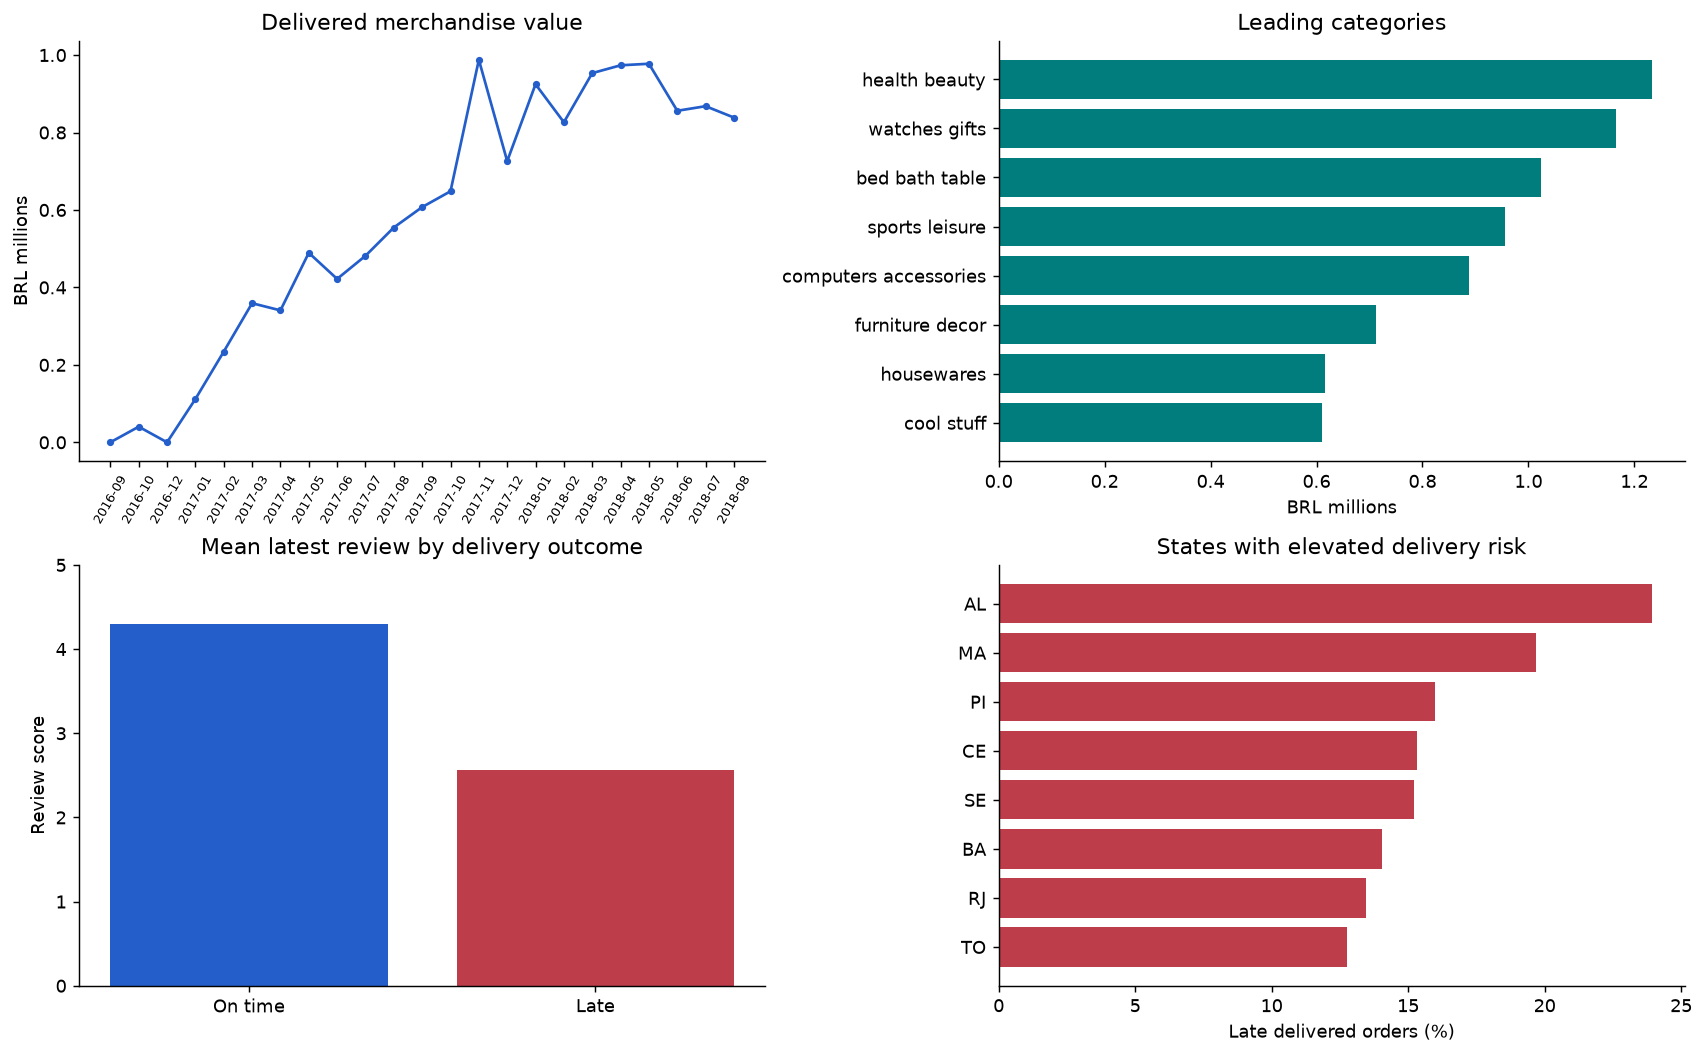

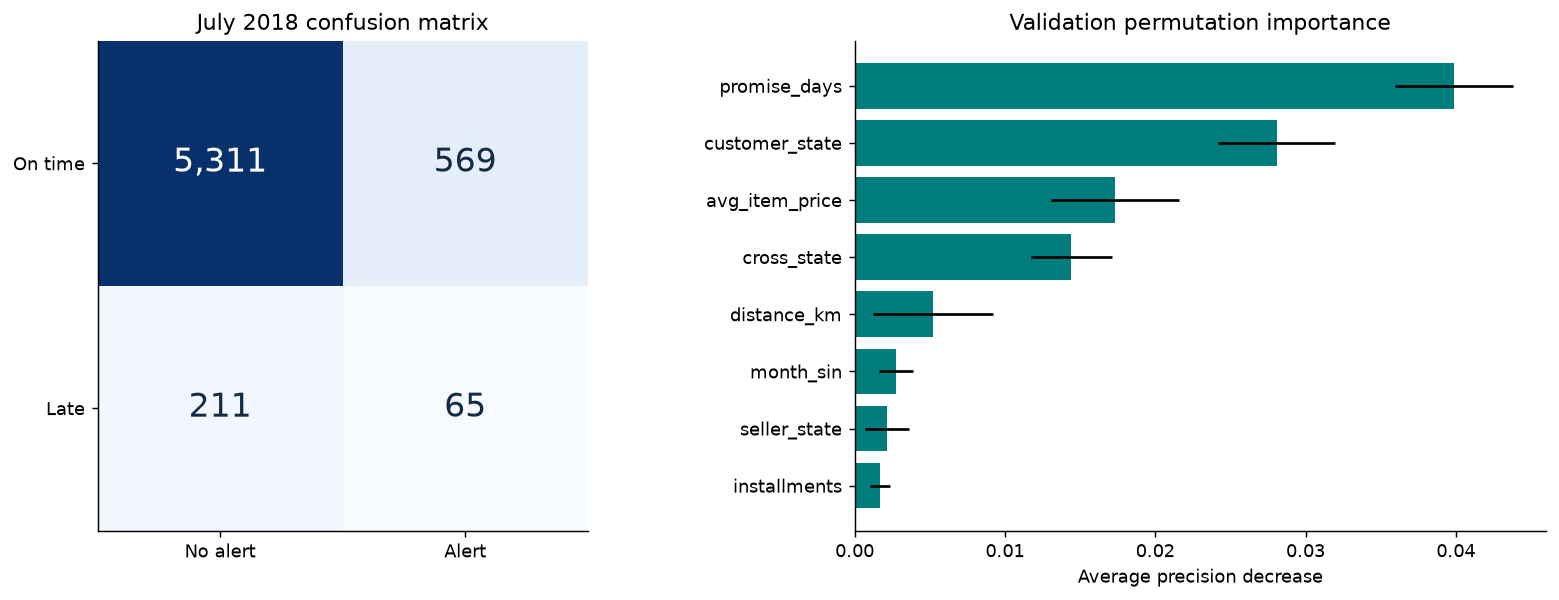

In [11]:

import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':130,'font.size':10,'axes.spines.top':False,'axes.spines.right':False})
fig,ax=plt.subplots(2,2,figsize=(13,8),layout='constrained')
ax[0,0].plot(monthly.month,monthly.gmv/1e6,color='#245ecb',marker='o',markersize=3)
ax[0,0].set(title='Delivered merchandise value',ylabel='BRL millions')
ax[0,0].tick_params(axis='x',rotation=60,labelsize=7)
z=categories.head(8).iloc[::-1]
ax[0,1].barh(z.category.str.replace('_',' '),z.gmv/1e6,color='#007d7c')
ax[0,1].set(title='Leading categories',xlabel='BRL millions')
ax[1,0].bar(['On time','Late'],[statistics['ontime_review_mean'],statistics['late_review_mean']],color=['#245ecb','#bd3d4b'])
ax[1,0].set(title='Mean latest review by delivery outcome',ylabel='Review score',ylim=(0,5))
z=states.loc[states.eligible.ge(100)].sort_values('late_rate').tail(8)
ax[1,1].barh(z.customer_state,z.late_rate*100,color='#bd3d4b')
ax[1,1].set(title='States with elevated delivery risk',xlabel='Late delivered orders (%)')
plt.show()
fig,ax=plt.subplots(1,2,figsize=(12,4.5),layout='constrained')
cm=np.array([[best['tn'],best['fp']],[best['fn'],best['tp']]])
ax[0].imshow(cm,cmap='Blues')
for row in range(2):
    for col in range(2):ax[0].text(col,row,f'{cm[row,col]:,}',ha='center',va='center',color='white' if cm[row,col]>cm.max()/2 else '#152b45',fontsize=18)
ax[0].set(xticks=[0,1],xticklabels=['No alert','Alert'],yticks=[0,1],yticklabels=['On time','Late'],title='July 2018 confusion matrix')
z=imp.head(8).iloc[::-1]
ax[1].barh(z.feature,z.importance,xerr=z['std'],color='#007d7c')
ax[1].set(title='Validation permutation importance',xlabel='Average precision decrease')
plt.show()


## 11. Executive interpretation and next actions

In [12]:

from IPython.display import Markdown, display
b=result['selected_model']; op=result['opportunity']; ss=result['summary']; st=result['statistics']
text=f"""
Five findings matter most:

1. Delivered GMV is **BRL {ss['gmv']:,.0f}** across **{ss['delivered_orders']:,} orders**. Jan-Jul GMV grew **{ss['jan_jul_gmv_growth']:.1%}** versus the prior-year window, largely alongside order-volume growth (**{ss['jan_jul_order_growth']:.1%}**).
2. Five categories contribute **{ss['top5_category_share']:.1%}** of GMV. SP, RJ and MG contribute **{ss['top3_state_share']:.1%}**. Concentration identifies where improvements affect the most value.
3. **{ss['repeat_rate']:.1%}** of delivered customers repeat within the extract. The mature-cohort 90-day repeat measure is **{ss['repeat_within_90days']:.2%}**, so retention should be tested with equal follow-up windows.
4. **{ss['late_rate']:.2%}** of eligible deliveries are late. Their mean review is **{st['late_review_mean']:.2f}**, compared with **{st['ontime_review_mean']:.2f}** on time. The mean gap is **{st['difference']:.2f}** points (95% CI {st['difference_ci'][0]:.2f} to {st['difference_ci'][1]:.2f}). Observational data cannot establish causality.
5. **{b['model']}** won validation. July test ROC-AUC is **{b['roc_auc']:.3f}**, average precision **{b['average_precision']:.3f}**, recall **{b['recall']:.1%}**, and precision **{b['precision']:.1%}**. It flags **{b['alert_rate']:.1%}** of orders. This supports a controlled pilot, subject to workload and calibration checks.

**Three funded changes:**

- **Risk-alert pilot, operations owner, first 30 days.** Intervene on selected high-risk orders with a randomized holdout. Monitor late rate, review score, alerts/day and cost per late order avoided. At the frozen threshold, {op['model_flagged_test_orders']:,} July orders would receive alerts, including {op['model_flagged_late_test_orders']:,} actually late orders. A 20% intervention success assumption implies {op['model_scenario_20pct_flagged_late_avoided']:.0f} avoided late outcomes in that historical cohort. This scenario is not a forecast.
- **Seller/route review, logistics owner, 30-60 days.** Review {op['priority_sellers']} sellers meeting the volume and Wilson-bound screen. Their deduplicated portfolio includes {op['priority_late_orders']:,} late orders. A 20% reduction corresponds to about {op['scenario_late_orders_avoided']:.0f} fewer late outcomes and BRL {op['scenario_gmv_exposure_addressed']:,.0f} of associated merchandise exposure. Validate seller root causes and current-period stability before action.
- **Second-purchase experiment, CRM owner, 60-90 days.** Target {op['retention_target_customers']:,} recent high-value first-time buyers in the snapshot. A one-percentage-point incremental repeat uplift gives about {op['retention_scenario_extra_orders']:.0f} additional orders, or BRL {op['retention_scenario_extra_gmv_at_market_aov']:,.0f} at overall AOV before offer costs. Measure incremental margin, not just redemptions.

**Limits:** GMV is not platform revenue. No margin, take rate, refunds or intervention costs are available. The final model test is July 2018 and must be revalidated in current operations. April-June was diagnostic and informed the calendar correction. Delivered-only labels omit unresolved and cancelled orders. Verify checkout feature snapshots, calibrate scores, and run a randomized pilot before scaling.
"""
display(Markdown(text))



Five findings matter most:

1. Delivered GMV is **BRL 13,221,498** across **96,478 orders**. Jan-Jul GMV grew **161.6%** versus the prior-year window, largely alongside order-volume growth (**160.8%**).
2. Five categories contribute **39.8%** of GMV. SP, RJ and MG contribute **63.4%**. Concentration identifies where improvements affect the most value.
3. **3.0%** of delivered customers repeat within the extract. The mature-cohort 90-day repeat measure is **2.28%**, so retention should be tested with equal follow-up windows.
4. **8.11%** of eligible deliveries are late. Their mean review is **2.57**, compared with **4.29** on time. The mean gap is **-1.73** points (95% CI -1.77 to -1.69). Observational data cannot establish causality.
5. **Logistic regression** won validation. July test ROC-AUC is **0.690**, average precision **0.097**, recall **23.6%**, and precision **10.3%**. It flags **10.3%** of orders. This supports a controlled pilot, subject to workload and calibration checks.

**Three funded changes:**

- **Risk-alert pilot, operations owner, first 30 days.** Intervene on selected high-risk orders with a randomized holdout. Monitor late rate, review score, alerts/day and cost per late order avoided. At the frozen threshold, 634 July orders would receive alerts, including 65 actually late orders. A 20% intervention success assumption implies 13 avoided late outcomes in that historical cohort. This scenario is not a forecast.
- **Seller/route review, logistics owner, 30-60 days.** Review 35 sellers meeting the volume and Wilson-bound screen. Their deduplicated portfolio includes 1,781 late orders. A 20% reduction corresponds to about 356 fewer late outcomes and BRL 44,192 of associated merchandise exposure. Validate seller root causes and current-period stability before action.
- **Second-purchase experiment, CRM owner, 60-90 days.** Target 4,226 recent high-value first-time buyers in the snapshot. A one-percentage-point incremental repeat uplift gives about 42 additional orders, or BRL 5,791 at overall AOV before offer costs. Measure incremental margin, not just redemptions.

**Limits:** GMV is not platform revenue. No margin, take rate, refunds or intervention costs are available. The final model test is July 2018 and must be revalidated in current operations. April-June was diagnostic and informed the calendar correction. Delivered-only labels omit unresolved and cancelled orders. Verify checkout feature snapshots, calibrate scores, and run a randomized pilot before scaling.
